# Equalized-odds post-processing (Hardt et al., 2016) on Adult, German and COMPAS

Fairlearn's `ThresholdOptimizer` gives each group its own threshold on a trained model's scores, so that true and false positive rates are equal across groups.

**Run:** `pip install fairlearn scikit-learn pandas matplotlib`, then *Run All*.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fairlearn.postprocessing import ThresholdOptimizer, plot_threshold_optimizer
from fairlearn.metrics import equalized_odds_difference
from sklearn.compose import make_column_transformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEEDS = 10   # number of random train/test splits
K = 5        # neighbours for the consistency metric

## 1. Data
`y = 1` is the favourable outcome. `group` is the protected attribute, with the privileged group listed first: Adult = sex (Male), German = age (> 25), COMPAS = race (Caucasian).

In [ ]:
URL = "https://raw.githubusercontent.com/"

def load_adult():
    cols = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status", "occupation",
            "relationship", "race", "sex", "capital_gain", "capital_loss", "hours_per_week", "country", "income"]
    df = pd.read_csv(URL + "jbrownlee/Datasets/master/adult-all.csv", names=cols, na_values="?",
                     skipinitialspace=True).dropna().reset_index(drop=True)
    y = df.income.str.startswith(">50K").astype(int)
    return df.drop(columns=["income", "fnlwgt", "education"]), y, df.sex, "Male"

def load_german():
    df = pd.read_csv(URL + "jbrownlee/Datasets/master/german.csv", header=None)
    df.columns = [f"a{i}" for i in range(1, 21)] + ["credit"]
    df = df.rename(columns={"a13": "age"})
    df["sex"] = np.where(df.a9.isin(["A92", "A95"]), "female", "male")   # a9 = personal status & sex
    y = (df.credit == 1).astype(int)
    group = pd.Series(np.where(df.age > 25, "age > 25", "age <= 25"))
    return df.drop(columns=["credit", "a9"]), y, group, "age > 25"

def load_compas():
    df = pd.read_csv(URL + "propublica/compas-analysis/master/compas-scores-two-years.csv")
    df = df[df.days_b_screening_arrest.between(-30, 30) & (df.is_recid != -1) & (df.c_charge_degree != "O")
            & (df.score_text != "N/A") & df.race.isin(["African-American", "Caucasian"])].reset_index(drop=True)
    X = df[["age", "juv_fel_count", "juv_misd_count", "juv_other_count", "priors_count",
            "sex", "age_cat", "race", "c_charge_degree"]]
    return X, 1 - df.two_year_recid, df.race, "Caucasian"

DATA = {"adult": load_adult(), "german": load_german(), "compas": load_compas()}
pd.DataFrame({n: {"rows": len(y), "P(y=1)": y.mean().round(3)} for n, (X, y, g, p) in DATA.items()}).T

,rows,P(y=1)
adult,45222.0,0.248
german,1000.0,0.700
compas,5278.0,0.530


## 2. Metrics
- **DP_Diff** = P(ŷ=1 | unprivileged) − P(ŷ=1 | privileged); ideal 0.
- **DIR** = P(ŷ=1 | unprivileged) / P(ŷ=1 | privileged); ideal 1, and below 0.8 fails the 80% rule.
- **Consistency** = 1 − the mean gap between each prediction and those of its 5 nearest neighbours; ideal 1.
- **EOdds gap** = the largest group difference in TPR or FPR; ideal 0. This is what the method targets.

In [ ]:
def consistency(Z, y):
    algo = "ball_tree" if len(Z) <= 10000 else "brute"   # same search as AIF360; brute force for speed on Adult
    idx = NearestNeighbors(n_neighbors=K, algorithm=algo).fit(Z).kneighbors(Z, return_distance=False)
    return 1 - np.mean(np.abs(y - y[idx].mean(axis=1)))

def fairness(Z, y, priv):
    p_unpriv, p_priv = y[~priv].mean(), y[priv].mean()
    return {"DP_Diff": p_unpriv - p_priv, "DIR": p_unpriv / p_priv, "Consistency": consistency(Z, y)}

def preprocessor(X):
    num = X.select_dtypes("number").columns
    cat = [c for c in X.columns if c not in num]
    return make_column_transformer((StandardScaler(), num),
                                   (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))

## 3. Before mitigation: the original labels

In [ ]:
rows = []
for name, (X, y, group, priv) in DATA.items():
    Z = preprocessor(X).fit_transform(X)
    rows.append({"dataset": name, "stage": "Original labels", **fairness(Z, y.to_numpy(), (group == priv).to_numpy())})
pd.DataFrame(rows).set_index("dataset").round(3)

,stage,DP_Diff,DIR,Consistency
dataset,,,,
adult,Original labels,-0.199,0.363,0.839
german,Original labels,-0.149,0.795,0.742
compas,Original labels,-0.132,0.783,0.658


## 4. Mitigation pipeline
For each seed:
1. Split the data 70/30 into train and test, stratified on label × group.
2. Train a logistic regression on 70% of the training set.
3. Fit the post-processor on the other 30% of the training set.
4. Evaluate both models on the test set.

In [ ]:
def run(name, seed):
    X, y, group, priv = DATA[name]
    y, group = y.to_numpy(), group.to_numpy()
    strata = y * 2 + (group == priv)
    train, test = train_test_split(np.arange(len(y)), test_size=0.3, stratify=strata, random_state=seed)
    fit, post = train_test_split(train, test_size=0.3, stratify=strata[train], random_state=seed)

    model = make_pipeline(preprocessor(X), LogisticRegression(max_iter=2000)).fit(X.iloc[fit], y[fit])
    mitigator = ThresholdOptimizer(estimator=model, constraints="equalized_odds", prefit=True,
                                   predict_method="predict_proba")
    mitigator.fit(X.iloc[post], y[post], sensitive_features=group[post])

    Z = model[0].transform(X.iloc[test])
    preds = {"Baseline": model.predict(X.iloc[test]),
             "Post-processed": mitigator.predict(X.iloc[test], sensitive_features=group[test], random_state=seed)}
    rows = []
    for stage, p in preds.items():
        rows.append({"dataset": name, "stage": stage, "seed": seed, **fairness(Z, p, group[test] == priv),
                     "EOdds": equalized_odds_difference(y[test], p, sensitive_features=group[test]),
                     "Accuracy": accuracy_score(y[test], p), "Bal_Acc": balanced_accuracy_score(y[test], p)})
    return rows, mitigator

results, mitigators = [], {}
for name in DATA:
    for seed in range(SEEDS):
        r, m = run(name, seed)
        results += r
        if seed == 0:
            mitigators[name] = m
results = pd.DataFrame(rows + results)

## 5. Results (test set, mean ± std over 10 seeds)

In [ ]:
order = {"Original labels": 0, "Baseline": 1, "Post-processed": 2}
metrics = ["DP_Diff", "DIR", "Consistency", "EOdds", "Accuracy", "Bal_Acc"]
g = results.groupby(["dataset", "stage"])[metrics]
mean, std = g.mean().map("{:.3f}".format), g.std().map("{:.3f}".format)
table = (mean + " ± " + std).where(std != "nan", mean).replace("nan", "–")
table.reindex(pd.MultiIndex.from_product([list(DATA), list(order)]))

DP_Diff            DIR    Consistency  \
adult  Original labels          -0.199          0.363          0.839   
       Baseline         -0.190 ± 0.005  0.289 ± 0.013  0.962 ± 0.001   
       Post-processed   -0.093 ± 0.009  0.562 ± 0.030  0.942 ± 0.003   
german Original labels          -0.149          0.795          0.742   
       Baseline         -0.155 ± 0.037  0.804 ± 0.052  0.811 ± 0.016   
       Post-processed   -0.049 ± 0.049  0.943 ± 0.057  0.870 ± 0.087   
compas Original labels          -0.132          0.783          0.658   
       Baseline         -0.275 ± 0.019  0.628 ± 0.018  0.964 ± 0.004   
       Post-processed   -0.037 ± 0.038  0.942 ± 0.064  0.893 ± 0.032   

                                EOdds       Accuracy        Bal_Acc  
adult  Original labels              –              –              –  
       Baseline         0.114 ± 0.020  0.846 ± 0.002  0.765 ± 0.004  
       Post-processed   0.022 ± 0.012  0.830 ± 0.003  0.728 ± 0.011  
german Original labels              –              –              –  
       Baseline         0.138 ± 0.056  0.748 ± 0.013  0.670 ± 0.021  
       Post-processed   0.082 ± 0.066  0.727 ± 0.019  0.599 ± 0.060  
compas Original labels              –              –              –  
       Baseline         0.304 ± 0.034  0.674 ± 0.008  0.671 ± 0.008  
       Post-processed   0.058 ± 0.029  0.643 ± 0.016  0.636 ± 0.021

## 6. Figures

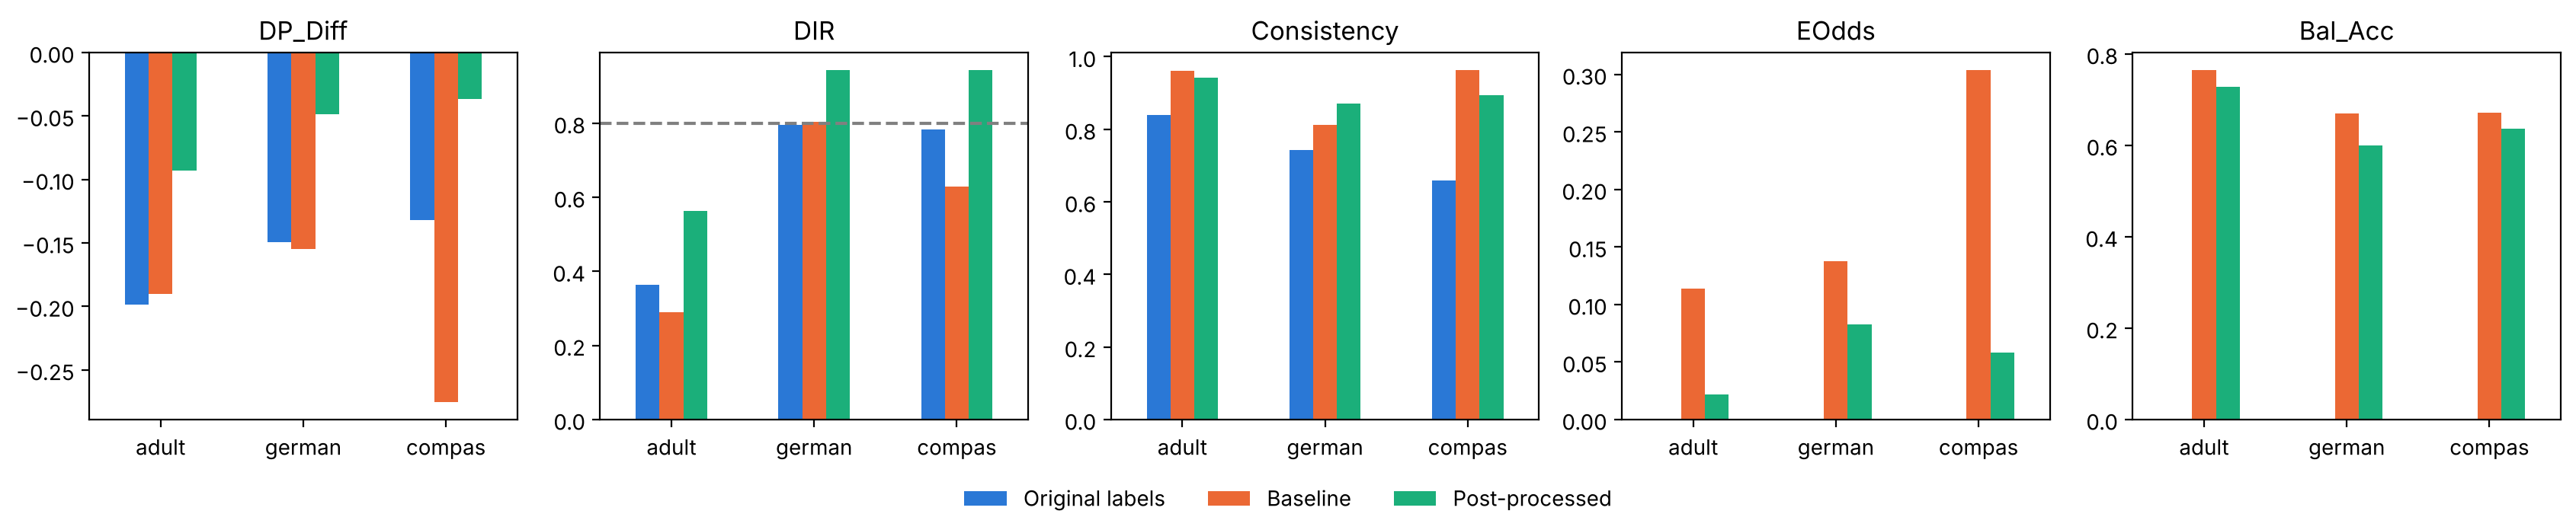

In [ ]:
means = results.groupby(["dataset", "stage"])[["DP_Diff", "DIR", "Consistency", "EOdds", "Bal_Acc"]].mean()
fig, axes = plt.subplots(1, 5, figsize=(17, 3.5))
for ax, m in zip(axes, means.columns):
    means[m].unstack()[list(order)].loc[list(DATA)].plot.bar(ax=ax, rot=0, legend=False,
                                                             color=["#2a78d6", "#eb6834", "#1baf7a"])
    ax.set_title(m)
    ax.set_xlabel("")
axes[1].axhline(0.8, ls="--", c="gray")   # 80% rule
fig.legend(list(order), loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.08, 1, 1))

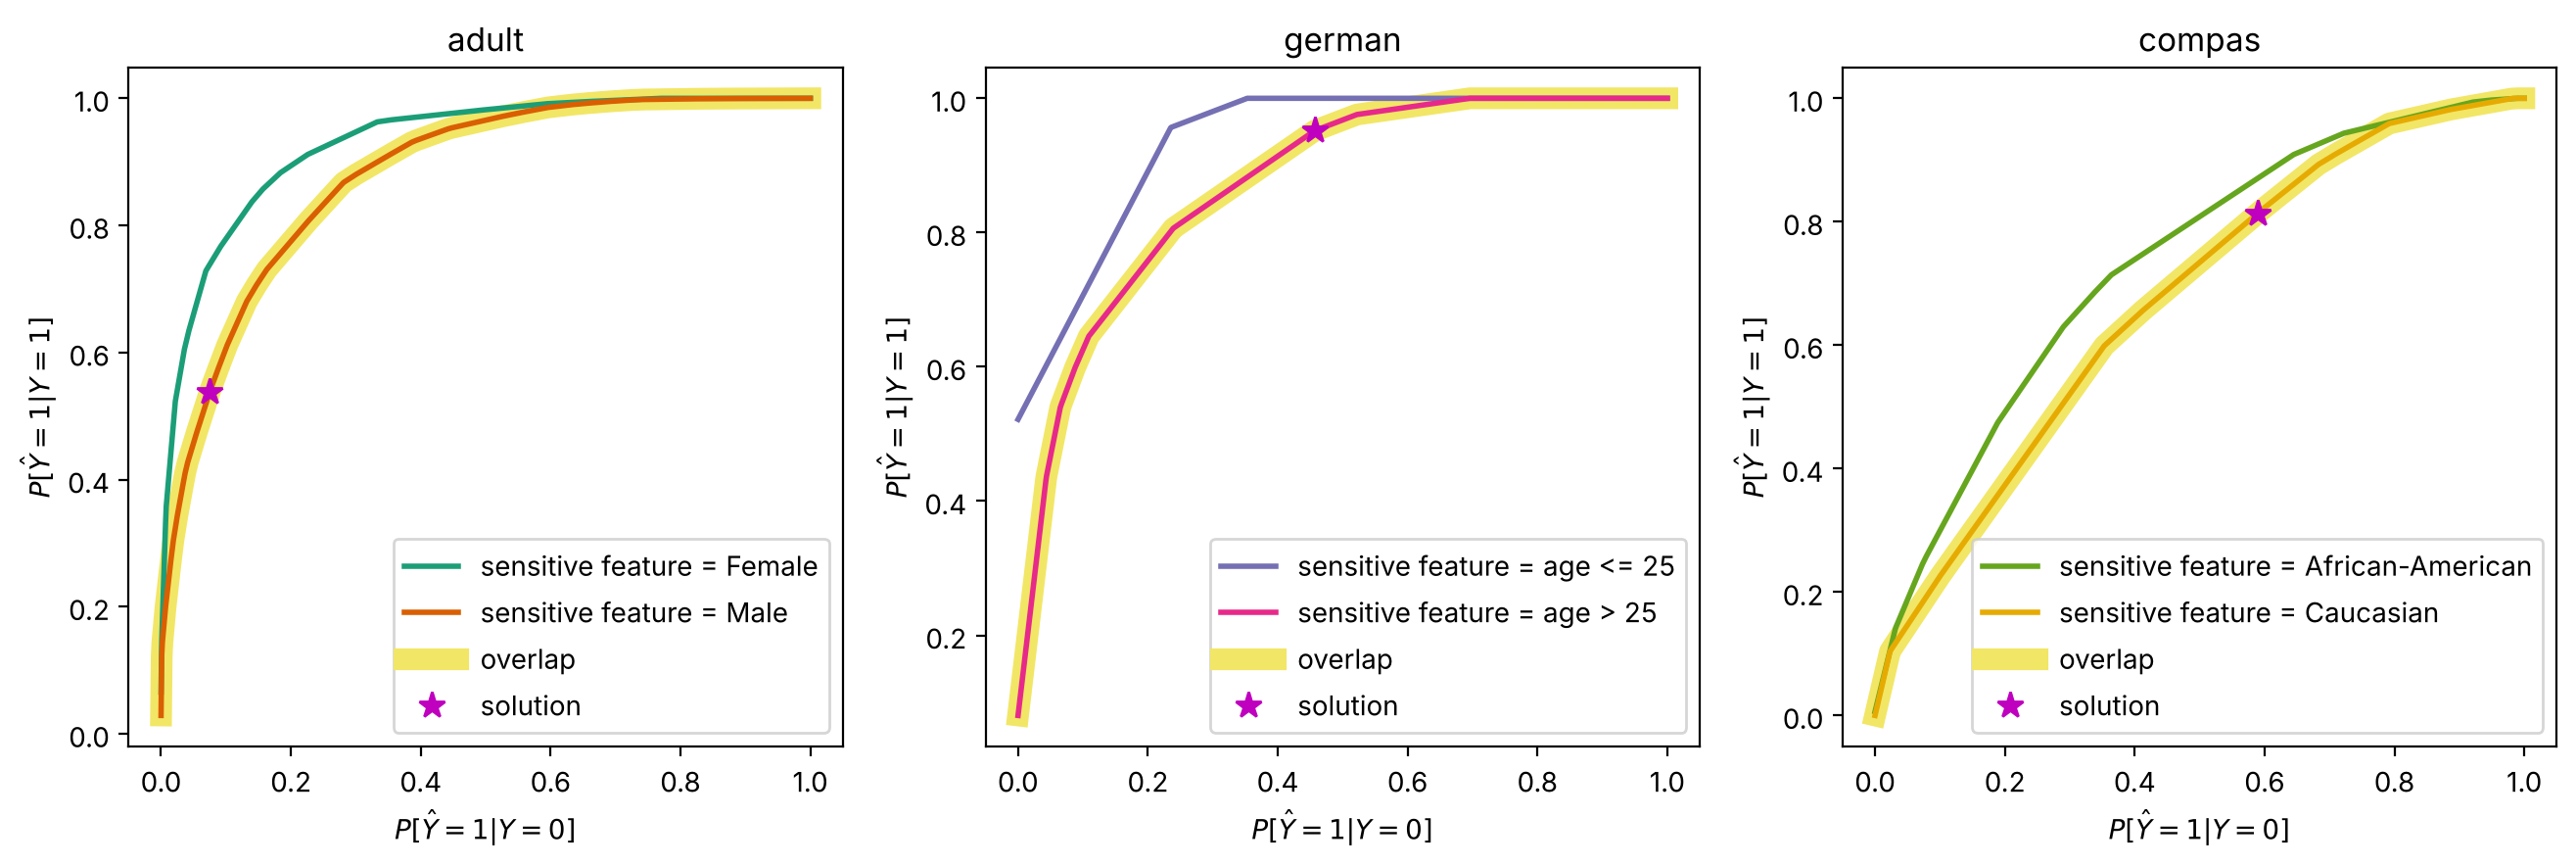

In [ ]:
# Per-group ROC hulls and the equalized-odds point chosen by the method (seed 0)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, m) in zip(axes, mitigators.items()):
    plot_threshold_optimizer(m, ax=ax, show_plot=False)
    ax.set_title(name)